<a href="https://colab.research.google.com/github/DrashtiShah23/data266-2046/blob/main/hw7/HW7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA 266 Homework: GAN Concepts and Autoencoders on FashionMNIST

In [1]:
# Required personal parameters and reproducibility setup
SID4 = 2046
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4 = {SID4}")
print(f"SEED = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")
assert (SID4, SEED, SLICE, HP_ID, CLS_A, CLS_B) == (2046, 2046, 46, 0, 6, 3)


SID4 = 2046
SEED = 2046
SLICE = 46
HP_ID = 0
CLS_A = 6
CLS_B = 3


## 1. Fundamental Architecture of a GAN

A Generative Adversarial Network, or GAN, consists of two neural networks that are trained against each other: a **generator** and a **discriminator**.

The **generator** is responsible for creating synthetic data. It starts with a random noise vector and transforms it through a neural network to produce an output that resembles samples from the real training data. For an image dataset, for example, the generator learns to turn random noise into realistic looking images. Initially, these generated images are usually poor, but they improve as training progresses.

The **discriminator** acts as a classifier. It receives both real samples from the training dataset and fake samples produced by the generator, and tries to determine whether each sample is real or generated. Its output represents how likely it believes a sample came from the real data distribution.

During training, the two networks have opposing objectives. The discriminator is trained to correctly distinguish real samples from generated ones. The generator is trained to produce samples that are convincing enough to fool the discriminator. As the discriminator becomes better at identifying fake samples, the generator receives stronger feedback about where its generated data differs from real data and adjusts its parameters accordingly.

This creates an **adversarial training process**. The discriminator can be viewed as continuously improving its ability to detect counterfeits, while the generator continuously improves its ability to create them. Neither network is trained independently because improvement in one network changes the learning problem faced by the other.

The theoretical goal is for the generator to learn the underlying probability distribution of the real training data. In the ideal equilibrium, the generated distribution matches the real data distribution closely enough that the discriminator can no longer reliably distinguish between them. At this point, the discriminator would assign approximately a **50% probability** to whether a sample is real or generated, meaning that the generator has successfully learned to produce samples that are statistically indistinguishable from the real data.


## 2. Mode Collapse

**Mode collapse** is a common failure in GAN training where the generator learns to produce only a small variety of outputs instead of representing the full diversity of the training data. For example, if a GAN is trained on FashionMNIST, it might discover that generating a particular type of shoe consistently fools the discriminator. Instead of learning to generate shirts, dresses, bags, shoes, and other items, it may repeatedly generate similar looking shoes.

This happens because the generator is rewarded for **fooling the discriminator**, not directly for producing diverse outputs. If the generator discovers a small set of outputs that currently work well against the discriminator, it can repeatedly produce variations of those outputs. GAN training is also unstable because the generator and discriminator are continuously changing in response to each other. If one network becomes much stronger than the other, the training signal can become weak or unstable, making collapse more likely.

One technique used to reduce mode collapse is **minibatch discrimination**. A normal discriminator evaluates samples mostly independently, which can make it difficult to recognize that the generator is repeatedly producing nearly identical outputs. Minibatch discrimination allows the discriminator to compare samples within the same batch. If many generated samples are extremely similar, the discriminator can recognize this lack of diversity and classify them as fake. The generator is therefore encouraged to produce a wider variety of outputs.

Another approach is the **Wasserstein GAN, or WGAN**. The original GAN objective can provide poor or unstable gradients when the real and generated distributions have little overlap, especially early in training. WGAN replaces the original divergence based objective with the Wasserstein distance, which provides a smoother and more informative measure of how far the generated distribution is from the real distribution. This generally gives the generator more useful gradients and makes training more stable. Later approaches such as WGAN GP further improve this by using a gradient penalty to enforce the constraints required by the Wasserstein objective.

Both approaches address mode collapse differently. Minibatch discrimination directly encourages diversity by helping the discriminator detect repetitive outputs, while WGAN improves the optimization process so that the generator receives more stable feedback and is less likely to settle on only a few successful outputs.




## 3. Significant GAN Variants

#### DCGAN

**Deep Convolutional GAN, or DCGAN**, was introduced to make GANs more effective and stable when generating images. The original GAN architecture relied mainly on fully connected layers, which do not take advantage of the spatial structure present in images.

DCGAN replaces these layers with **convolutional neural networks**. The discriminator uses strided convolutions to learn spatial features from images, while the generator uses transposed convolutions to progressively transform a latent vector into an image. It also introduced architectural practices such as batch normalization and carefully chosen activation functions to improve training stability.

The main contribution of DCGAN was showing that GANs could learn useful hierarchical image features and generate significantly better images by designing the generator and discriminator specifically for visual data.


#### Conditional GAN

A standard GAN gives the user little control over what the generator produces because generation depends mainly on random noise. A **Conditional GAN, or cGAN**, addresses this limitation by giving both the generator and discriminator additional information about the desired output.

This information can be a class label or another form of context. For example, when training on FashionMNIST, instead of simply asking the generator to produce a random clothing image, we could provide the label for **Dress** and ask it to generate an image belonging specifically to that class.

The generator therefore learns a conditional distribution rather than only the overall data distribution. The discriminator also receives the condition so that it evaluates not only whether an image looks real, but whether it is consistent with the requested condition. This makes GAN generation much more controllable and is useful when specific categories or attributes need to be generated.


#### CycleGAN

**CycleGAN** addresses a different problem: translating images between two domains when paired examples are not available. Traditional supervised image translation usually requires corresponding pairs, such as the exact same scene represented in two different styles. Collecting such paired datasets can be difficult or impossible.

CycleGAN instead learns using **unpaired datasets**. It uses two generators and two discriminators. One generator learns a transformation from domain A to domain B, while the second learns the reverse transformation from B to A.

Its major innovation is **cycle consistency loss**. If an image is transformed from A to B and then transformed back from B to A, the final image should resemble the original. For example, if the model converts a horse image into a zebra and then converts that generated zebra back into a horse, the reconstructed image should remain close to the original horse.

This cycle consistency constraint prevents the generators from making arbitrary transformations while still allowing the model to learn without paired examples. As a result, CycleGAN can perform tasks such as changing seasons, transferring artistic styles, or translating between visual domains using independently collected datasets.

## 2. FC Autoencoder and Variational Autoencoder on FashionMNIST

For the experimental portion of this assignment, I train and evaluate two autoencoder architectures on FashionMNIST: a fully connected autoencoder and a variational autoencoder.

The experiments use my assigned reproducibility parameters from SID4 = 2046. The same train, validation, and test data setup is used for both models so their results can be compared consistently.

In [2]:
import random
import sys
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2 as T

from tqdm.auto import tqdm

COOL_COLORS = {
    "mint": "#8ED1B2",
    "rose": "#E8A0BF",
    "lavender": "#B8A1E3",
    "teal": "#4FA6A6"
}

SID4 = 2046
SEED = 2046
SLICE = 46
HP_ID = 0
CLS_A = 6
CLS_B = 3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("SID4:", SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)
print("Device:", device)
print("PyTorch:", torch.__version__)
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

SID4: 2046
SEED: 2046
SLICE: 46
HP_ID: 0
CLS_A: 6
CLS_B: 3
Device: cpu
PyTorch: 2.11.0+cpu
Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


### FashionMNIST Dataset

FashionMNIST contains 28 × 28 grayscale images from 10 clothing categories. Each image is converted to a floating point tensor with pixel values in the range [0, 1] and flattened from 28 × 28 into a 784 dimensional vector for the fully connected networks.

I use the assigned SEED for the train and validation split and for DataLoader shuffling so that the experiment is reproducible.

In [3]:
transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Lambda(lambda x: torch.flatten(x))
])

full_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

print("Full training set:", len(full_train))
print("Test set:", len(test_dataset))
print("Input shape:", full_train[0][0].shape)

Full training set: 60000
Test set: 10000
Input shape: torch.Size([784])


In [4]:
train_dataset, val_dataset = random_split(
    full_train,
    [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 256

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = full_train.classes

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))
print("Number of classes:", len(class_names))
print("CLS_A:", CLS_A, class_names[CLS_A])
print("CLS_B:", CLS_B, class_names[CLS_B])

Training examples: 54000
Validation examples: 6000
Test examples: 10000
Number of classes: 10
CLS_A: 6 Shirt
CLS_B: 3 Dress


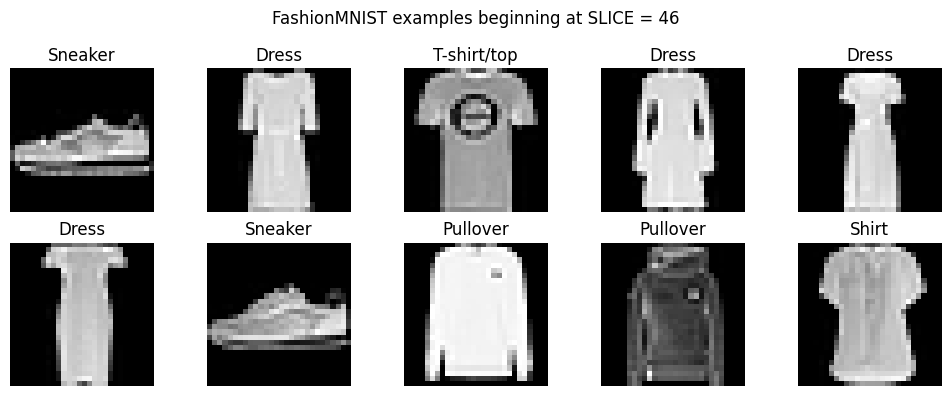

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for j, ax in enumerate(axes.flat):
    image, label = full_train[SLICE + j]

    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle(f"FashionMNIST examples beginning at SLICE = {SLICE}")
plt.tight_layout()
plt.show()

In [6]:
x_batch, y_batch = next(iter(train_loader))

print("Batch image shape:", x_batch.shape)
print("Batch label shape:", y_batch.shape)
print("Pixel minimum:", x_batch.min().item())
print("Pixel maximum:", x_batch.max().item())

assert x_batch.shape[1] == 784
assert 0.0 <= x_batch.min().item()
assert x_batch.max().item() <= 1.0

print("Dataset pipeline checks passed.")

Batch image shape: torch.Size([256, 784])
Batch label shape: torch.Size([256])
Pixel minimum: 0.0
Pixel maximum: 1.0
Dataset pipeline checks passed.


### Fully Connected Autoencoder

The fully connected autoencoder learns a compressed representation of each FashionMNIST image. The encoder reduces the 784 dimensional input to a smaller latent representation, while the decoder reconstructs the original image from that representation.

Because the input pixels are scaled to the range [0, 1], the decoder uses a sigmoid activation at its output. The model is trained by minimizing mean squared reconstruction error between the original and reconstructed images.


In [7]:
class FCAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction


LATENT_DIM = 32

fc_ae = FCAutoencoder(latent_dim=LATENT_DIM).to(device)

print(fc_ae)

total_params = sum(p.numel() for p in fc_ae.parameters())
trainable_params = sum(
    p.numel() for p in fc_ae.parameters() if p.requires_grad
)

print()
print("Latent dimension:", LATENT_DIM)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

FCAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

Latent dimension: 32
Total parameters: 476,720
Trainable parameters: 476,720


In [8]:
x_batch, _ = next(iter(train_loader))
x_batch = x_batch.to(device)

with torch.no_grad():
    reconstruction = fc_ae(x_batch)

print("Input shape:", x_batch.shape)
print("Reconstruction shape:", reconstruction.shape)

assert reconstruction.shape == x_batch.shape
assert torch.isfinite(reconstruction).all()

print("FC Autoencoder forward pass successful.")

Input shape: torch.Size([256, 784])
Reconstruction shape: torch.Size([256, 784])
FC Autoencoder forward pass successful.


#### Training Configuration

The FC Autoencoder is optimized with Adam using mean squared error as the reconstruction loss. Validation loss is measured after every epoch using the held out validation set.

The same validation data will later be used while training the VAE so that the two models are evaluated under a consistent experimental setup.

In [9]:
FC_LR = 1e-3
FC_EPOCHS = 15

fc_criterion = nn.MSELoss()
fc_optimizer = optim.Adam(fc_ae.parameters(), lr=FC_LR)

print("Optimizer: Adam")
print("Learning rate:", FC_LR)
print("Epochs:", FC_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Loss: Mean Squared Error")

Optimizer: Adam
Learning rate: 0.001
Epochs: 15
Batch size: 256
Loss: Mean Squared Error


In [10]:
def train_fc_epoch(model, loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    total_samples = 0

    for x, _ in loader:
        x = x.to(device)

        optimizer.zero_grad()

        reconstruction = model(x)
        loss = criterion(reconstruction, x)

        loss.backward()
        optimizer.step()

        batch_size = x.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / total_samples


@torch.no_grad()
def evaluate_fc(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    for x, _ in loader:
        x = x.to(device)

        reconstruction = model(x)
        loss = criterion(reconstruction, x)

        batch_size = x.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / total_samples

In [11]:
fc_train_losses = []
fc_val_losses = []

best_fc_val_loss = float("inf")
best_fc_state = None

for epoch in range(1, FC_EPOCHS + 1):
    train_loss = train_fc_epoch(
        fc_ae,
        train_loader,
        fc_optimizer,
        fc_criterion,
        device
    )

    val_loss = evaluate_fc(
        fc_ae,
        val_loader,
        fc_criterion,
        device
    )

    fc_train_losses.append(train_loss)
    fc_val_losses.append(val_loss)

    if val_loss < best_fc_val_loss:
        best_fc_val_loss = val_loss

        best_fc_state = {
            key: value.detach().cpu().clone()
            for key, value in fc_ae.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d}/{FC_EPOCHS} "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

fc_ae.load_state_dict(best_fc_state)

print()
print("Best validation loss:", f"{best_fc_val_loss:.6f}")

Epoch 01/15 Train Loss: 0.051892 Val Loss: 0.028535
Epoch 02/15 Train Loss: 0.024799 Val Loss: 0.022118
Epoch 03/15 Train Loss: 0.020751 Val Loss: 0.018953
Epoch 04/15 Train Loss: 0.018391 Val Loss: 0.017470
Epoch 05/15 Train Loss: 0.017191 Val Loss: 0.016595
Epoch 06/15 Train Loss: 0.016393 Val Loss: 0.015949
Epoch 07/15 Train Loss: 0.015776 Val Loss: 0.015470
Epoch 08/15 Train Loss: 0.015262 Val Loss: 0.014844
Epoch 09/15 Train Loss: 0.014755 Val Loss: 0.014407
Epoch 10/15 Train Loss: 0.014354 Val Loss: 0.013993
Epoch 11/15 Train Loss: 0.013988 Val Loss: 0.013618
Epoch 12/15 Train Loss: 0.013626 Val Loss: 0.013250
Epoch 13/15 Train Loss: 0.013247 Val Loss: 0.013069
Epoch 14/15 Train Loss: 0.012915 Val Loss: 0.012677
Epoch 15/15 Train Loss: 0.012637 Val Loss: 0.012408

Best validation loss: 0.012408


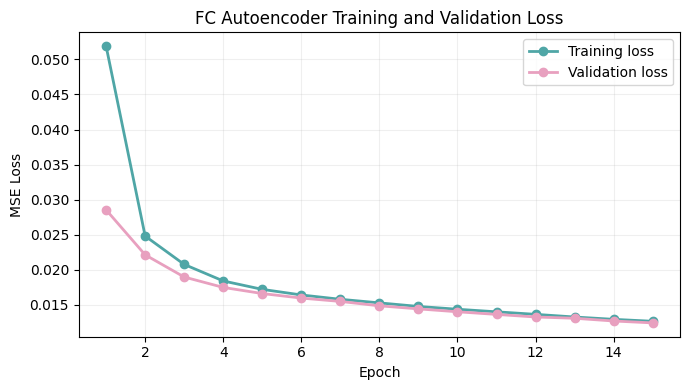

In [12]:
plt.figure(figsize=(7, 4))

epochs = range(1, FC_EPOCHS + 1)

plt.plot(
    epochs,
    fc_train_losses,
    marker="o",
    linewidth=2,
    color=COOL_COLORS["teal"],
    label="Training loss"
)

plt.plot(
    epochs,
    fc_val_losses,
    marker="o",
    linewidth=2,
    color=COOL_COLORS["rose"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("FC Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [13]:
fc_test_loss = evaluate_fc(
    fc_ae,
    test_loader,
    fc_criterion,
    device
)

print("FC Autoencoder results")
print("Best validation MSE:", f"{best_fc_val_loss:.6f}")
print("Test MSE:", f"{fc_test_loss:.6f}")

FC Autoencoder results
Best validation MSE: 0.012408
Test MSE: 0.012584


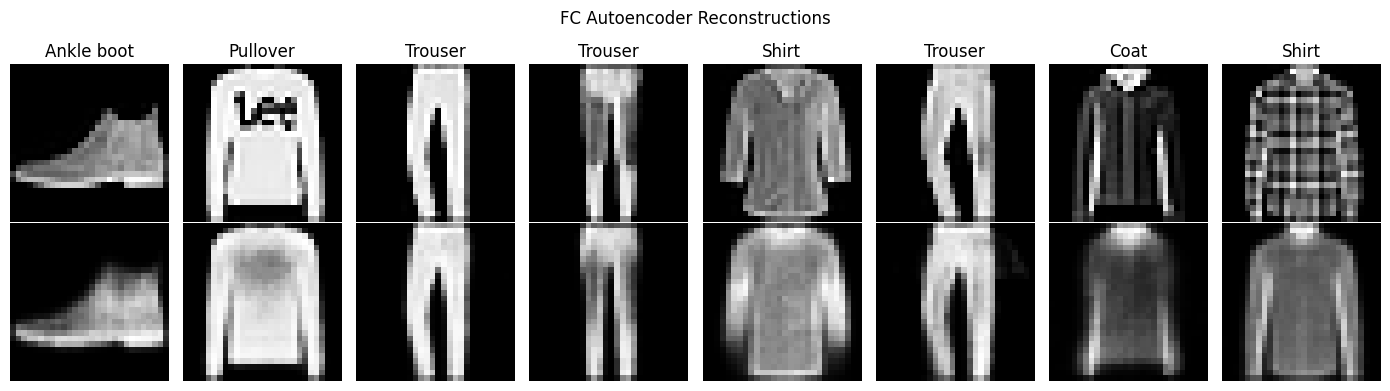

In [14]:
fc_ae.eval()

test_images, test_labels = next(iter(test_loader))
test_images_device = test_images.to(device)

with torch.no_grad():
    reconstructed_images = fc_ae(test_images_device).cpu()

n_examples = 8

fig, axes = plt.subplots(2, n_examples, figsize=(14, 4))

for i in range(n_examples):
    axes[0, i].imshow(
        test_images[i].reshape(28, 28),
        cmap="gray"
    )
    axes[0, i].set_title(class_names[test_labels[i]])
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_images[i].reshape(28, 28),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")

plt.suptitle("FC Autoencoder Reconstructions")
plt.tight_layout()
plt.show()

### Variational Autoencoder

Unlike the standard autoencoder, the Variational Autoencoder learns a probability distribution in the latent space rather than mapping each input to one fixed latent vector.

The encoder produces a mean and log variance for each latent dimension. A latent vector is then sampled from this distribution using the reparameterization trick. This allows sampling to remain differentiable during training.

The VAE objective combines reconstruction loss with KL divergence. Reconstruction loss encourages accurate reconstruction of the input, while KL divergence regularizes the learned latent distribution toward a standard normal distribution. This produces a smoother and more structured latent space that can also be sampled to generate new examples.

In [15]:
class VAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)

        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)

        return reconstruction, mu, logvar


vae = VAE(latent_dim=LATENT_DIM).to(device)

print(vae)

vae_total_params = sum(p.numel() for p in vae.parameters())
vae_trainable_params = sum(
    p.numel() for p in vae.parameters() if p.requires_grad
)

print()
print("Latent dimension:", LATENT_DIM)
print("Total parameters:", f"{vae_total_params:,}")
print("Trainable parameters:", f"{vae_trainable_params:,}")

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=128, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=32, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

Latent dimension: 32
Total parameters: 480,848
Trainable parameters: 480,848


In [16]:
x_batch, _ = next(iter(train_loader))
x_batch = x_batch.to(device)

vae.eval()

with torch.no_grad():
    reconstruction, mu, logvar = vae(x_batch)

print("Input shape:", x_batch.shape)
print("Mean shape:", mu.shape)
print("Log variance shape:", logvar.shape)
print("Reconstruction shape:", reconstruction.shape)

assert mu.shape == (x_batch.shape[0], LATENT_DIM)
assert logvar.shape == mu.shape
assert reconstruction.shape == x_batch.shape

assert torch.isfinite(mu).all()
assert torch.isfinite(logvar).all()
assert torch.isfinite(reconstruction).all()

print("VAE forward pass successful.")

Input shape: torch.Size([256, 784])
Mean shape: torch.Size([256, 32])
Log variance shape: torch.Size([256, 32])
Reconstruction shape: torch.Size([256, 784])
VAE forward pass successful.


#### VAE Loss

The VAE is optimized using two components.

The reconstruction component measures how accurately the decoder reproduces the original image. Binary cross entropy is used because the input pixels have been scaled to the range [0, 1].

The KL divergence term measures how far the encoder's learned latent distribution is from a standard normal distribution. Minimizing this term regularizes the latent space and makes meaningful sampling possible.

The training objective is the sum of reconstruction loss and KL divergence. I track both components separately so that their behavior can be examined rather than reporting only the combined VAE objective.

In [17]:
def vae_loss_function(reconstruction, x, mu, logvar):
    reconstruction_loss = nn.functional.binary_cross_entropy(
        reconstruction,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = reconstruction_loss + kl_loss

    return total_loss, reconstruction_loss, kl_loss

In [18]:
VAE_LR = 1e-3
VAE_EPOCHS = 15

vae_optimizer = optim.Adam(
    vae.parameters(),
    lr=VAE_LR
)

print("Optimizer: Adam")
print("Learning rate:", VAE_LR)
print("Epochs:", VAE_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Latent dimension:", LATENT_DIM)
print("Objective: BCE reconstruction + KL divergence")

Optimizer: Adam
Learning rate: 0.001
Epochs: 15
Batch size: 256
Latent dimension: 32
Objective: BCE reconstruction + KL divergence


In [19]:
def train_vae_epoch(model, loader, optimizer, device):
    model.train()

    total_loss = 0.0
    total_reconstruction = 0.0
    total_kl = 0.0
    total_samples = 0

    for x, _ in loader:
        x = x.to(device)

        optimizer.zero_grad()

        reconstruction, mu, logvar = model(x)

        loss, reconstruction_loss, kl_loss = vae_loss_function(
            reconstruction,
            x,
            mu,
            logvar
        )

        loss.backward()
        optimizer.step()

        batch_size = x.size(0)

        total_loss += loss.item()
        total_reconstruction += reconstruction_loss.item()
        total_kl += kl_loss.item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_reconstruction / total_samples,
        total_kl / total_samples
    )


@torch.no_grad()
def evaluate_vae(model, loader, device):
    model.eval()

    total_loss = 0.0
    total_reconstruction = 0.0
    total_kl = 0.0
    total_samples = 0

    for x, _ in loader:
        x = x.to(device)

        reconstruction, mu, logvar = model(x)

        loss, reconstruction_loss, kl_loss = vae_loss_function(
            reconstruction,
            x,
            mu,
            logvar
        )

        batch_size = x.size(0)

        total_loss += loss.item()
        total_reconstruction += reconstruction_loss.item()
        total_kl += kl_loss.item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_reconstruction / total_samples,
        total_kl / total_samples
    )

In [20]:
vae_train_total = []
vae_train_reconstruction = []
vae_train_kl = []

vae_val_total = []
vae_val_reconstruction = []
vae_val_kl = []

best_vae_val_loss = float("inf")
best_vae_state = None

for epoch in range(1, VAE_EPOCHS + 1):
    train_total, train_recon, train_kl = train_vae_epoch(
        vae,
        train_loader,
        vae_optimizer,
        device
    )

    val_total, val_recon, val_kl = evaluate_vae(
        vae,
        val_loader,
        device
    )

    vae_train_total.append(train_total)
    vae_train_reconstruction.append(train_recon)
    vae_train_kl.append(train_kl)

    vae_val_total.append(val_total)
    vae_val_reconstruction.append(val_recon)
    vae_val_kl.append(val_kl)

    if val_total < best_vae_val_loss:
        best_vae_val_loss = val_total

        best_vae_state = {
            key: value.detach().cpu().clone()
            for key, value in vae.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d}/{VAE_EPOCHS} "
        f"Train: {train_total:.3f} "
        f"Val: {val_total:.3f} "
        f"Recon: {val_recon:.3f} "
        f"KL: {val_kl:.3f}"
    )

vae.load_state_dict(best_vae_state)

print()
print(
    "Best validation VAE loss:",
    f"{best_vae_val_loss:.3f}"
)

Epoch 01/15 Train: 328.392 Val: 284.203 Recon: 271.270 KL: 12.932
Epoch 02/15 Train: 275.574 Val: 265.932 Recon: 252.832 KL: 13.100
Epoch 03/15 Train: 262.810 Val: 257.910 Recon: 246.008 KL: 11.901
Epoch 04/15 Train: 257.005 Val: 254.016 Recon: 242.705 KL: 11.311
Epoch 05/15 Train: 253.957 Val: 251.523 Recon: 240.191 KL: 11.332
Epoch 06/15 Train: 251.879 Val: 249.656 Recon: 238.085 KL: 11.570
Epoch 07/15 Train: 250.193 Val: 248.041 Recon: 236.145 KL: 11.896
Epoch 08/15 Train: 248.753 Val: 247.234 Recon: 235.289 KL: 11.945
Epoch 09/15 Train: 247.515 Val: 245.970 Recon: 233.581 KL: 12.388
Epoch 10/15 Train: 246.344 Val: 244.724 Recon: 232.385 KL: 12.339
Epoch 11/15 Train: 245.382 Val: 244.002 Recon: 231.726 KL: 12.276
Epoch 12/15 Train: 244.671 Val: 243.401 Recon: 230.928 KL: 12.474
Epoch 13/15 Train: 244.026 Val: 242.983 Recon: 230.449 KL: 12.534
Epoch 14/15 Train: 243.555 Val: 242.467 Recon: 230.180 KL: 12.287
Epoch 15/15 Train: 243.116 Val: 241.953 Recon: 229.265 KL: 12.688

Best vali

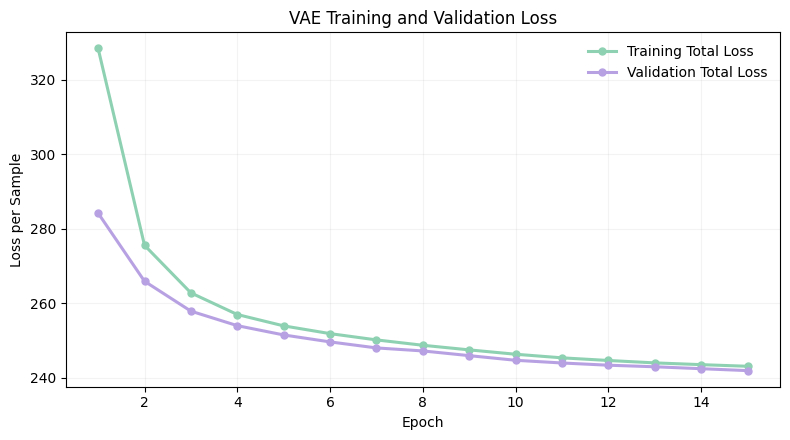

In [22]:
plt.figure(figsize=(8, 4.5))

epochs = range(1, VAE_EPOCHS + 1)

plt.plot(
    epochs,
    vae_train_total,
    marker="o",
    markersize=5,
    linewidth=2.2,
    color=COOL_COLORS["mint"],
    label="Training Total Loss"
)

plt.plot(
    epochs,
    vae_val_total,
    marker="o",
    markersize=5,
    linewidth=2.2,
    color=COOL_COLORS["lavender"],
    label="Validation Total Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss per Sample")
plt.title("VAE Training and Validation Loss")

plt.legend(frameon=False)
plt.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [23]:
vae_test_total, vae_test_recon, vae_test_kl = evaluate_vae(
    vae,
    test_loader,
    device
)

print("VAE results")
print("Test total loss:", f"{vae_test_total:.3f}")
print("Test reconstruction BCE:", f"{vae_test_recon:.3f}")
print("Test KL divergence:", f"{vae_test_kl:.3f}")

VAE results
Test total loss: 244.774
Test reconstruction BCE: 232.075
Test KL divergence: 12.699


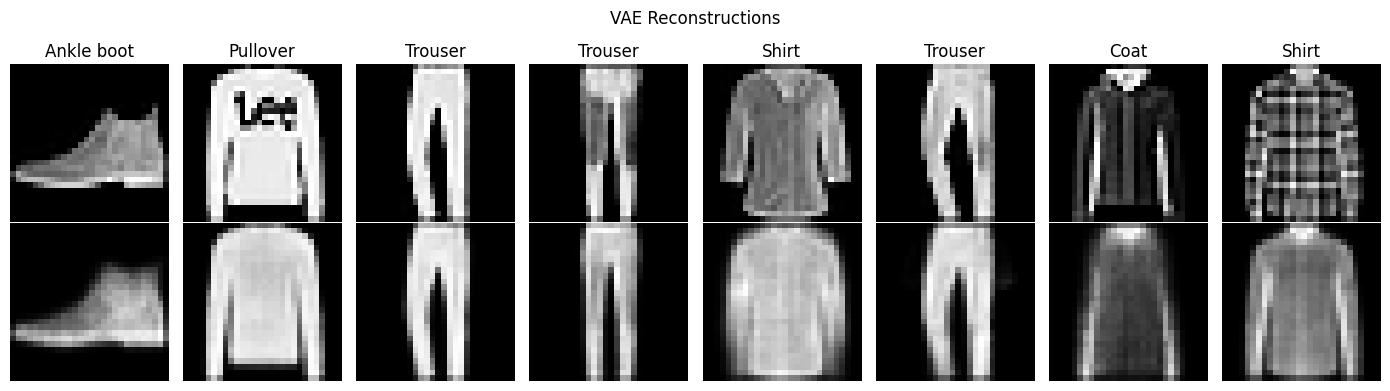

In [24]:
vae.eval()

test_images, test_labels = next(iter(test_loader))
test_images_device = test_images.to(device)

with torch.no_grad():
    mu, logvar = vae.encode(test_images_device)
    vae_reconstructed = vae.decode(mu).cpu()

n_examples = 8

fig, axes = plt.subplots(
    2,
    n_examples,
    figsize=(14, 4)
)

for i in range(n_examples):
    axes[0, i].imshow(
        test_images[i].reshape(28, 28),
        cmap="gray"
    )

    axes[0, i].set_title(
        class_names[test_labels[i]]
    )

    axes[0, i].axis("off")

    axes[1, i].imshow(
        vae_reconstructed[i].reshape(28, 28),
        cmap="gray"
    )

    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.suptitle("VAE Reconstructions")
plt.tight_layout()
plt.show()

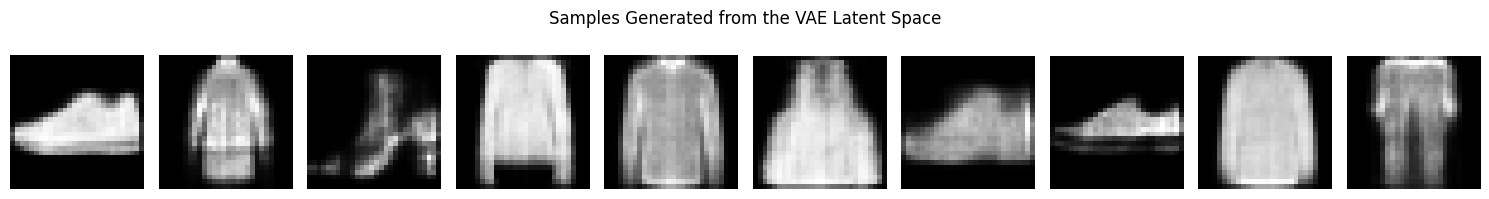

In [25]:
vae.eval()

torch.manual_seed(SEED)

with torch.no_grad():
    z = torch.randn(
        10,
        LATENT_DIM,
        device=device
    )

    generated_images = vae.decode(z).cpu()

fig, axes = plt.subplots(
    1,
    10,
    figsize=(15, 2)
)

for i, ax in enumerate(axes):
    ax.imshow(
        generated_images[i].reshape(28, 28),
        cmap="gray"
    )

    ax.axis("off")

plt.suptitle(
    "Samples Generated from the VAE Latent Space"
)

plt.tight_layout()
plt.show()

## 3. Model Comparison and Error Analysis

The FC Autoencoder and VAE use different training objectives, so their raw training losses are not directly comparable. The FC Autoencoder minimizes mean squared reconstruction error, while the VAE objective combines binary cross entropy reconstruction loss with KL divergence.

For a fair comparison, both trained models are evaluated on the same test set using mean squared error between each original image and its reconstruction. For the VAE, the latent mean is used during this comparison to obtain deterministic reconstructions.

I also examine reconstruction performance for my assigned focus classes, CLS_A = 6 (Shirt) and CLS_B = 3 (Dress), and inspect the highest error examples to understand where each model fails.

In [26]:
fc_ae.eval()
vae.eval()

all_images = []
all_labels = []

all_fc_recon = []
all_vae_recon = []

all_fc_mse = []
all_vae_mse = []

with torch.no_grad():
    for x, labels in test_loader:
        x_device = x.to(device)

        fc_recon = fc_ae(x_device)

        mu, logvar = vae.encode(x_device)
        vae_recon = vae.decode(mu)

        fc_mse = torch.mean(
            (fc_recon - x_device) ** 2,
            dim=1
        )

        vae_mse = torch.mean(
            (vae_recon - x_device) ** 2,
            dim=1
        )

        all_images.append(x.cpu())
        all_labels.append(labels.cpu())

        all_fc_recon.append(fc_recon.cpu())
        all_vae_recon.append(vae_recon.cpu())

        all_fc_mse.append(fc_mse.cpu())
        all_vae_mse.append(vae_mse.cpu())

all_images = torch.cat(all_images)
all_labels = torch.cat(all_labels)

all_fc_recon = torch.cat(all_fc_recon)
all_vae_recon = torch.cat(all_vae_recon)

all_fc_mse = torch.cat(all_fc_mse)
all_vae_mse = torch.cat(all_vae_mse)

print("Evaluated test images:", len(all_images))
print()
print("FC AE mean test MSE:", f"{all_fc_mse.mean().item():.6f}")
print("VAE mean test MSE:", f"{all_vae_mse.mean().item():.6f}")

Evaluated test images: 10000

FC AE mean test MSE: 0.012584
VAE mean test MSE: 0.016428


In [27]:
fc_mean_mse = all_fc_mse.mean().item()
vae_mean_mse = all_vae_mse.mean().item()

fc_rmse = np.sqrt(fc_mean_mse)
vae_rmse = np.sqrt(vae_mean_mse)

print("Common reconstruction metrics")
print()
print(
    f"{'Model':<12}"
    f"{'MSE':>12}"
    f"{'RMSE':>12}"
)

print(
    f"{'FC AE':<12}"
    f"{fc_mean_mse:>12.6f}"
    f"{fc_rmse:>12.6f}"
)

print(
    f"{'VAE':<12}"
    f"{vae_mean_mse:>12.6f}"
    f"{vae_rmse:>12.6f}"
)

Common reconstruction metrics

Model                MSE        RMSE
FC AE           0.012584    0.112177
VAE             0.016428    0.128171


In [28]:
class_results = []

for class_id, class_name in enumerate(class_names):
    mask = all_labels == class_id

    fc_class_mse = all_fc_mse[mask].mean().item()
    vae_class_mse = all_vae_mse[mask].mean().item()

    class_results.append(
        (
            class_id,
            class_name,
            fc_class_mse,
            vae_class_mse
        )
    )

print(
    f"{'ID':<5}"
    f"{'Class':<15}"
    f"{'FC AE MSE':>15}"
    f"{'VAE MSE':>15}"
)

for class_id, class_name, fc_mse, vae_mse in class_results:
    print(
        f"{class_id:<5}"
        f"{class_name:<15}"
        f"{fc_mse:>15.6f}"
        f"{vae_mse:>15.6f}"
    )

ID   Class                FC AE MSE        VAE MSE
0    T-shirt/top           0.011586       0.015432
1    Trouser               0.006662       0.009205
2    Pullover              0.011613       0.015845
3    Dress                 0.011551       0.015666
4    Coat                  0.010825       0.014759
5    Sandal                0.019117       0.024031
6    Shirt                 0.012350       0.015830
7    Sneaker               0.009435       0.012639
8    Bag                   0.019950       0.024339
9    Ankle boot            0.012747       0.016533


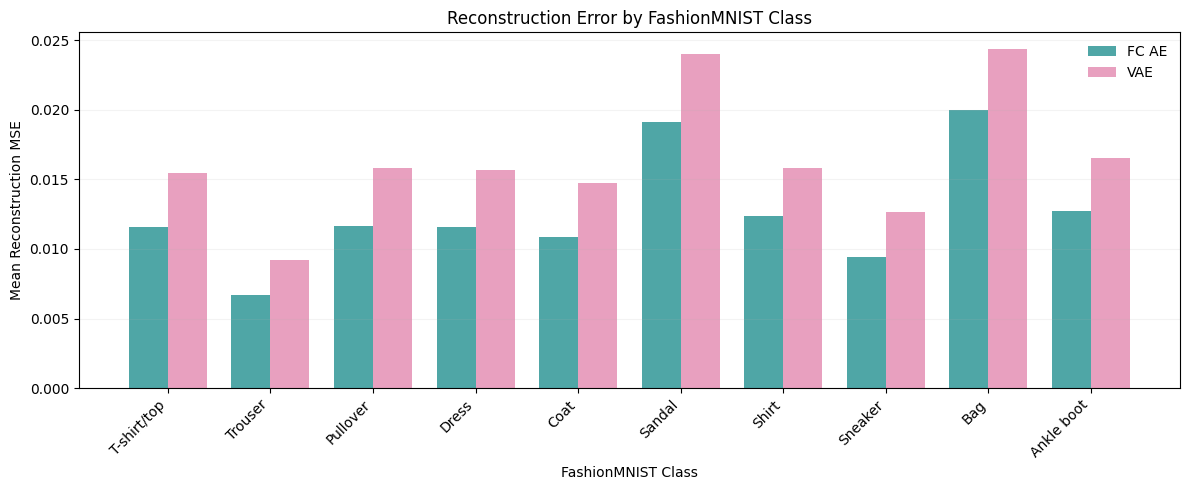

In [29]:
class_labels = [
    result[1]
    for result in class_results
]

fc_class_values = [
    result[2]
    for result in class_results
]

vae_class_values = [
    result[3]
    for result in class_results
]

x_positions = np.arange(len(class_labels))
width = 0.38

plt.figure(figsize=(12, 5))

plt.bar(
    x_positions - width / 2,
    fc_class_values,
    width,
    color=COOL_COLORS["teal"],
    label="FC AE"
)

plt.bar(
    x_positions + width / 2,
    vae_class_values,
    width,
    color=COOL_COLORS["rose"],
    label="VAE"
)

plt.xticks(
    x_positions,
    class_labels,
    rotation=45,
    ha="right"
)

plt.ylabel("Mean Reconstruction MSE")
plt.xlabel("FashionMNIST Class")
plt.title("Reconstruction Error by FashionMNIST Class")

plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.15)

plt.tight_layout()
plt.show()

### Assigned Focus Classes

My assigned classes are CLS_A = 6 (Shirt) and CLS_B = 3 (Dress). I examine these classes separately to determine whether the two architectures behave differently on the required class pair.

In [30]:
for focus_class in [CLS_A, CLS_B]:
    mask = all_labels == focus_class

    fc_focus = all_fc_mse[mask]
    vae_focus = all_vae_mse[mask]

    print(
        f"Class {focus_class}: "
        f"{class_names[focus_class]}"
    )

    print(
        "Number of test examples:",
        mask.sum().item()
    )

    print(
        "FC AE mean MSE:",
        f"{fc_focus.mean().item():.6f}"
    )

    print(
        "VAE mean MSE:",
        f"{vae_focus.mean().item():.6f}"
    )

    print(
        "FC AE median MSE:",
        f"{fc_focus.median().item():.6f}"
    )

    print(
        "VAE median MSE:",
        f"{vae_focus.median().item():.6f}"
    )

    print()

Class 6: Shirt
Number of test examples: 1000
FC AE mean MSE: 0.012350
VAE mean MSE: 0.015830
FC AE median MSE: 0.009588
VAE median MSE: 0.012589

Class 3: Dress
Number of test examples: 1000
FC AE mean MSE: 0.011551
VAE mean MSE: 0.015666
FC AE median MSE: 0.009450
VAE median MSE: 0.013641



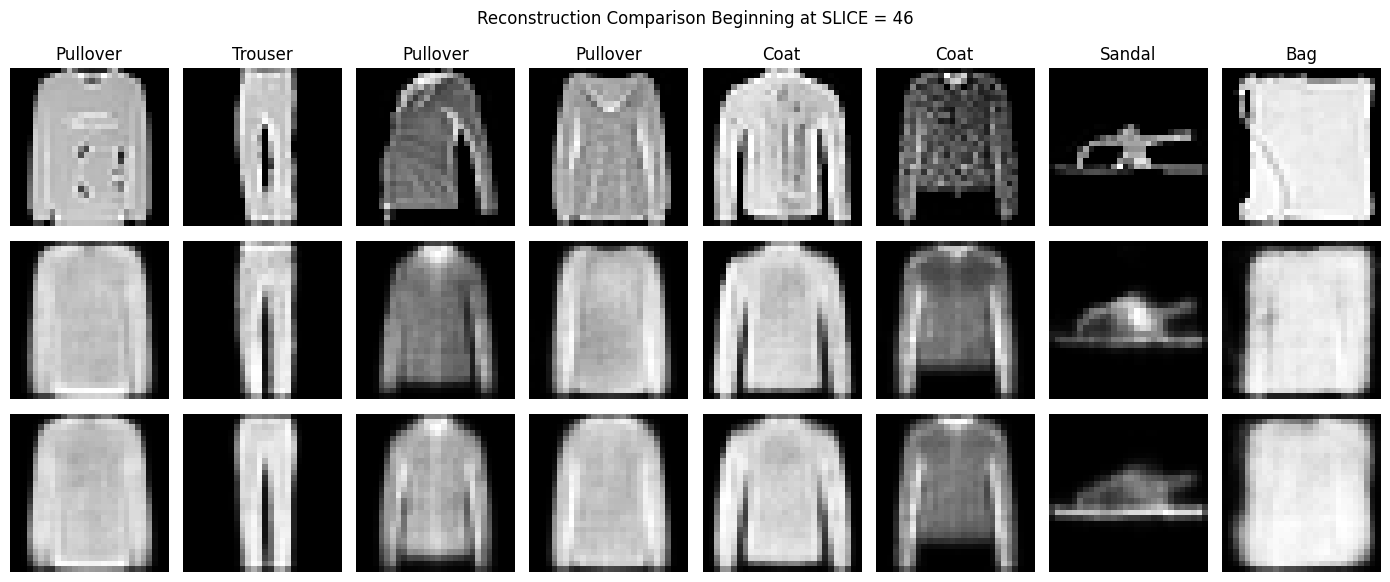

In [31]:
comparison_indices = [
    SLICE + i
    for i in range(8)
]

fig, axes = plt.subplots(
    3,
    len(comparison_indices),
    figsize=(14, 6)
)

for column, idx in enumerate(comparison_indices):
    axes[0, column].imshow(
        all_images[idx].reshape(28, 28),
        cmap="gray"
    )

    axes[0, column].set_title(
        class_names[all_labels[idx].item()]
    )

    axes[1, column].imshow(
        all_fc_recon[idx].reshape(28, 28),
        cmap="gray"
    )

    axes[2, column].imshow(
        all_vae_recon[idx].reshape(28, 28),
        cmap="gray"
    )

    for row in range(3):
        axes[row, column].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("FC AE")
axes[2, 0].set_ylabel("VAE")

plt.suptitle(
    f"Reconstruction Comparison Beginning at SLICE = {SLICE}"
)

plt.tight_layout()
plt.show()

### Reconstruction Failure Analysis

High reconstruction error identifies examples where a model has difficulty preserving the original image. Rather than selecting failures visually, I rank the test examples by reconstruction MSE and inspect the highest error cases.

This provides a reproducible way to identify difficult examples and helps determine what visual characteristics are associated with poor reconstruction.

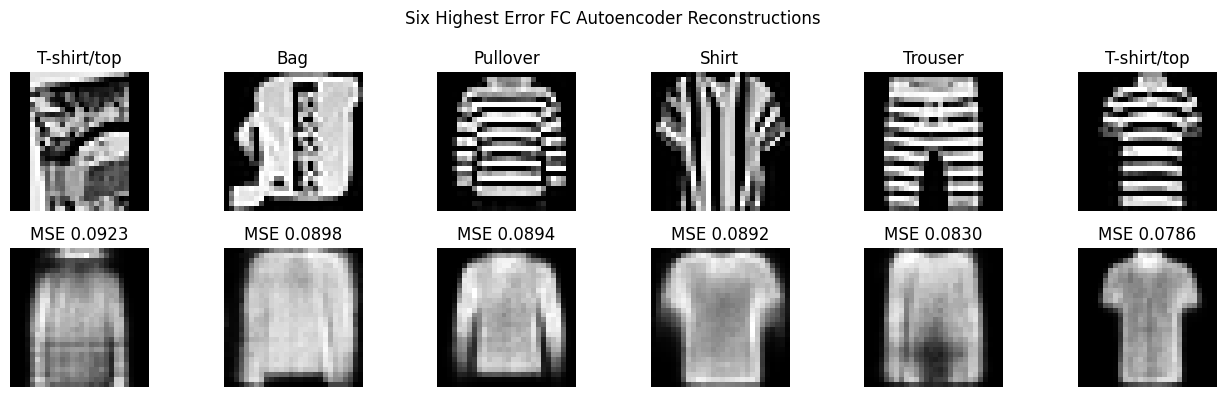

In [32]:
NUM_FAILURES = 6

fc_worst_indices = torch.topk(
    all_fc_mse,
    NUM_FAILURES
).indices

fig, axes = plt.subplots(
    2,
    NUM_FAILURES,
    figsize=(13, 4)
)

for column, idx_tensor in enumerate(fc_worst_indices):
    idx = idx_tensor.item()

    axes[0, column].imshow(
        all_images[idx].reshape(28, 28),
        cmap="gray"
    )

    axes[0, column].set_title(
        class_names[all_labels[idx].item()]
    )

    axes[1, column].imshow(
        all_fc_recon[idx].reshape(28, 28),
        cmap="gray"
    )

    axes[1, column].set_title(
        f"MSE {all_fc_mse[idx]:.4f}"
    )

    axes[0, column].axis("off")
    axes[1, column].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("FC AE")

plt.suptitle(
    "Six Highest Error FC Autoencoder Reconstructions"
)

plt.tight_layout()
plt.show()

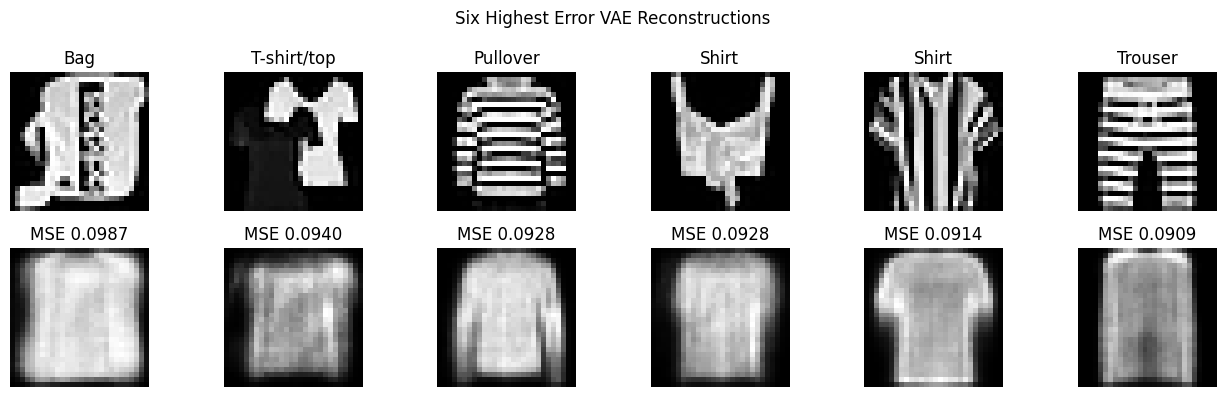

In [33]:
vae_worst_indices = torch.topk(
    all_vae_mse,
    NUM_FAILURES
).indices

fig, axes = plt.subplots(
    2,
    NUM_FAILURES,
    figsize=(13, 4)
)

for column, idx_tensor in enumerate(vae_worst_indices):
    idx = idx_tensor.item()

    axes[0, column].imshow(
        all_images[idx].reshape(28, 28),
        cmap="gray"
    )

    axes[0, column].set_title(
        class_names[all_labels[idx].item()]
    )

    axes[1, column].imshow(
        all_vae_recon[idx].reshape(28, 28),
        cmap="gray"
    )

    axes[1, column].set_title(
        f"MSE {all_vae_mse[idx]:.4f}"
    )

    axes[0, column].axis("off")
    axes[1, column].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.suptitle(
    "Six Highest Error VAE Reconstructions"
)

plt.tight_layout()
plt.show()

### Results Interpretation

Using the same reconstruction metric for both models, the FC Autoencoder achieved a lower overall test MSE of 0.012584 compared with 0.016428 for the VAE. The corresponding RMSE values were 0.112177 and 0.128171. This indicates that the FC Autoencoder reproduced the FashionMNIST test images more accurately at the pixel level.

The same pattern appeared in my assigned focus classes. For Shirt, the FC Autoencoder achieved a mean MSE of 0.012350 compared with 0.015830 for the VAE. For Dress, the FC Autoencoder achieved 0.011551 compared with 0.015666 for the VAE. The median errors also favored the FC Autoencoder for both classes, showing that the difference was not caused only by a small number of unusually difficult examples.

This result is reasonable because the two models optimize different objectives. The FC Autoencoder can concentrate entirely on reconstructing each input accurately. The VAE must also regularize its latent representation through the KL divergence term so that the latent space follows a structured distribution. This additional constraint can reduce reconstruction sharpness and accuracy, but it gives the VAE an important capability that the standard autoencoder does not naturally provide: meaningful sampling from the latent space to generate new examples.

Therefore, the FC Autoencoder performed better when reconstruction accuracy was the main criterion, while the VAE traded some reconstruction fidelity for a more structured and generative latent representation.

### Failure Analysis

The highest error reconstructions show that reconstruction difficulty is not distributed evenly across FashionMNIST examples. The difficult cases tend to contain shapes, boundaries, or internal details that are harder to preserve after compressing the original 784 dimensional image into a much smaller latent representation.

The FC Autoencoder generally preserves the overall silhouette of difficult examples, but some fine details and boundaries become smoothed or distorted. This is consistent with compression through a limited latent representation: the model retains the dominant structure while losing some of the less prominent pixel level information.

The VAE shows a similar pattern, but its difficult reconstructions tend to appear smoother and less sharply defined. This is consistent with the additional KL divergence constraint used during VAE training. Unlike the FC Autoencoder, the VAE is not optimizing reconstruction fidelity alone. It must also organize its latent representations so that they remain close to a standard normal distribution.

This helps explain the quantitative results. The FC Autoencoder achieved the lower overall reconstruction MSE, while the VAE sacrificed some pixel level accuracy in exchange for a structured latent space from which new samples can be generated. The failure examples therefore reinforce the same tradeoff observed in the test metrics rather than indicating that either model failed to train.

### Overall Comparison

The two models demonstrate different strengths on FashionMNIST. Using the same test set and reconstruction metric, the FC Autoencoder achieved an MSE of 0.012584 compared with 0.016428 for the VAE. The FC Autoencoder also produced lower reconstruction errors for both assigned focus classes, Shirt and Dress.

The FC Autoencoder is therefore the stronger model when the objective is accurate reconstruction of existing images. The VAE, however, provides functionality beyond reconstruction. Its probabilistic latent representation allows vectors to be sampled from the latent distribution and decoded into new FashionMNIST like examples.

Overall, the experiment demonstrates the main tradeoff between the architectures: a standard autoencoder can devote its representation entirely to reconstruction, while a VAE imposes additional structure on the latent space to support generative sampling. In this experiment, that additional structure came with a measurable reduction in reconstruction accuracy.

In [34]:
from pathlib import Path

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

fc_checkpoint_path = checkpoint_dir / "fc_autoencoder_sid2046.pt"
vae_checkpoint_path = checkpoint_dir / "vae_sid2046.pt"

torch.save(
    {
        "model_state_dict": fc_ae.state_dict(),
        "latent_dim": LATENT_DIM,
        "seed": SEED,
        "test_mse": fc_mean_mse
    },
    fc_checkpoint_path
)

torch.save(
    {
        "model_state_dict": vae.state_dict(),
        "latent_dim": LATENT_DIM,
        "seed": SEED,
        "test_mse": vae_mean_mse,
        "test_total_loss": vae_test_total,
        "test_reconstruction_bce": vae_test_recon,
        "test_kl": vae_test_kl
    },
    vae_checkpoint_path
)

print("Saved:", fc_checkpoint_path)
print("Saved:", vae_checkpoint_path)

Saved: checkpoints/fc_autoencoder_sid2046.pt
Saved: checkpoints/vae_sid2046.pt
